<a href="https://colab.research.google.com/github/amit809070/Machine-Learning-Lab-Assignments---M-tech-CSE/blob/main/Experiment%204.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 4-Lab Experiment 4: Principal Component Analysis (PCA)
Objective: To perform dimensionality reduction using PCA from scratch and using scikit-learn, and to visualize high-dimensional data.
Software / Tools Required:
•	Python 3.x, NumPy, Matplotlib, Scikit-learn
Procedure:
•	Load the Digits or Wine dataset.
•	Implement PCA by computing the covariance matrix and its eigenvectors from scratch.
•	Project the data onto the first two principal components and visualize.
•	Reconstruct the data and compute reconstruction error.
•	Compare results with sklearn.decomposition.PCA and plot explained variance ratio.
Expected Outcome: Understanding of dimensionality reduction, variance explanation, and data reconstruction.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Wine dataset

wine = load_wine()

X = wine.data
y = wine.target

print("Dataset Shape:", X.shape)

print("\nFeature Names:")
print(wine.feature_names)

print("\nTarget Classes:")
print(wine.target_names)

Dataset Shape: (178, 13)

Feature Names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Target Classes:
['class_0' 'class_1' 'class_2']


In [3]:
# Convert dataset into DataFrame

df = pd.DataFrame(
    X,
    columns=wine.feature_names
)

df["Target"] = y

print(df.head())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  Target  
0          

In [4]:
print("Dataset Information:\n")

print("Number of Samples:", X.shape[0])

print("Number of Features:", X.shape[1])

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Information:

Number of Samples: 178
Number of Features: 13

Missing Values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
Target                          0
dtype: int64

Statistical Summary:
          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.6

In [5]:
# Standardization

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original Data Shape:", X.shape)

print("Scaled Data Shape:", X_scaled.shape)

print("\nFirst 5 Rows:\n")

print(X_scaled[:5])

Original Data Shape: (178, 13)
Scaled Data Shape: (178, 13)

First 5 Rows:

[[ 1.51861254 -0.5622498   0.23205254 -1.16959318  1.91390522  0.80899739
   1.03481896 -0.65956311  1.22488398  0.25171685  0.36217728  1.84791957
   1.01300893]
 [ 0.24628963 -0.49941338 -0.82799632 -2.49084714  0.01814502  0.56864766
   0.73362894 -0.82071924 -0.54472099 -0.29332133  0.40605066  1.1134493
   0.96524152]
 [ 0.19687903  0.02123125  1.10933436 -0.2687382   0.08835836  0.80899739
   1.21553297 -0.49840699  2.13596773  0.26901965  0.31830389  0.78858745
   1.39514818]
 [ 1.69154964 -0.34681064  0.4879264  -0.80925118  0.93091845  2.49144552
   1.46652465 -0.98187536  1.03215473  1.18606801 -0.42754369  1.18407144
   2.33457383]
 [ 0.29570023  0.22769377  1.84040254  0.45194578  1.28198515  0.80899739
   0.66335127  0.22679555  0.40140444 -0.31927553  0.36217728  0.44960118
  -0.03787401]]


In [6]:
# Calculate feature-wise mean

mean = np.mean(X_scaled, axis=0)

# Center the data

X_centered = X_scaled - mean

print("Mean Values:\n", mean)

print("\nCentered Data Shape:", X_centered.shape)

Mean Values:
 [ 7.84141790e-15  2.44498554e-16 -4.05917497e-15 -7.11041712e-17
 -2.49488320e-17 -1.95536471e-16  9.44313292e-16 -4.17892936e-16
 -1.54059038e-15 -4.12903170e-16  1.39838203e-15  2.12688793e-15
 -6.98567296e-17]

Centered Data Shape: (178, 13)


In [7]:
# Calculate covariance matrix

cov_matrix = np.cov(
    X_centered,
    rowvar=False
)

print("Covariance Matrix:\n")

print(cov_matrix)

print("\nCovariance Matrix Shape:", cov_matrix.shape)

Covariance Matrix:

[[ 1.00564972  0.09493026  0.21273976 -0.31198788  0.27232816  0.29073446
   0.23815287 -0.15681042  0.13747022  0.549451   -0.07215255  0.07275191
   0.64735687]
 [ 0.09493026  1.00564972  0.16497228  0.29013035 -0.05488343 -0.3370606
  -0.41332866  0.29463237 -0.22199334  0.25039204 -0.56446685 -0.37079354
  -0.19309537]
 [ 0.21273976  0.16497228  1.00564972  0.44587209  0.28820583  0.12970824
   0.11572743  0.1872826   0.00970647  0.2603499  -0.07508874  0.00393333
   0.22488969]
 [-0.31198788  0.29013035  0.44587209  1.00564972 -0.0838039  -0.32292752
  -0.353355    0.36396647 -0.19844168  0.01883781 -0.27550299 -0.27833221
  -0.44308618]
 [ 0.27232816 -0.05488343  0.28820583 -0.0838039   1.00564972  0.21561254
   0.19688989 -0.25774204  0.23777643  0.20107967  0.05571118  0.06637684
   0.39557317]
 [ 0.29073446 -0.3370606   0.12970824 -0.32292752  0.21561254  1.00564972
   0.86944804 -0.45247731  0.61587304 -0.05544792  0.43613151  0.70390388
   0.50092909]
 [ 

In [8]:
# Calculate eigenvalues and eigenvectors

eigenvalues, eigenvectors = np.linalg.eigh(
    cov_matrix
)

print("Eigenvalues:\n")

print(eigenvalues)

print("\nEigenvectors Shape:")

print(eigenvectors.shape)

Eigenvalues:

[0.10396199 0.16972374 0.22706428 0.25232001 0.29051203 0.35046627
 0.55414147 0.64528221 0.85804868 0.92416587 1.45424187 2.51108093
 4.73243698]

Eigenvectors Shape:
(13, 13)


In [9]:
# Sort eigenvalues in descending order

sorted_indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[sorted_indices]

eigenvectors = eigenvectors[:, sorted_indices]

print("Sorted Eigenvalues:\n")

print(eigenvalues)

print("\nSorted Eigenvectors Shape:")

print(eigenvectors.shape)

Sorted Eigenvalues:

[4.73243698 2.51108093 1.45424187 0.92416587 0.85804868 0.64528221
 0.55414147 0.35046627 0.29051203 0.25232001 0.22706428 0.16972374
 0.10396199]

Sorted Eigenvectors Shape:
(13, 13)


In [10]:
# Select first two principal components

W = eigenvectors[:, :2]

print("First Two Principal Components:\n")

print(W)

print("\nSelected Components Shape:")

print(W.shape)

First Two Principal Components:

[[-0.1443294  -0.48365155]
 [ 0.24518758 -0.22493093]
 [ 0.00205106 -0.31606881]
 [ 0.23932041  0.0105905 ]
 [-0.14199204 -0.299634  ]
 [-0.39466085 -0.06503951]
 [-0.4229343   0.00335981]
 [ 0.2985331  -0.02877949]
 [-0.31342949 -0.03930172]
 [ 0.0886167  -0.52999567]
 [-0.29671456  0.27923515]
 [-0.37616741  0.16449619]
 [-0.28675223 -0.36490283]]

Selected Components Shape:
(13, 2)


In [11]:
# Transform original data into 2D

X_pca = np.dot(
    X_centered,
    W
)

print("Original Data Shape:", X_scaled.shape)

print("Reduced Data Shape:", X_pca.shape)

print("\nFirst 5 Projected Samples:\n")

print(X_pca[:5])

Original Data Shape: (178, 13)
Reduced Data Shape: (178, 2)

First 5 Projected Samples:

[[-3.31675081 -1.44346263]
 [-2.20946492  0.33339289]
 [-2.51674015 -1.0311513 ]
 [-3.75706561 -2.75637191]
 [-1.00890849 -0.86983082]]


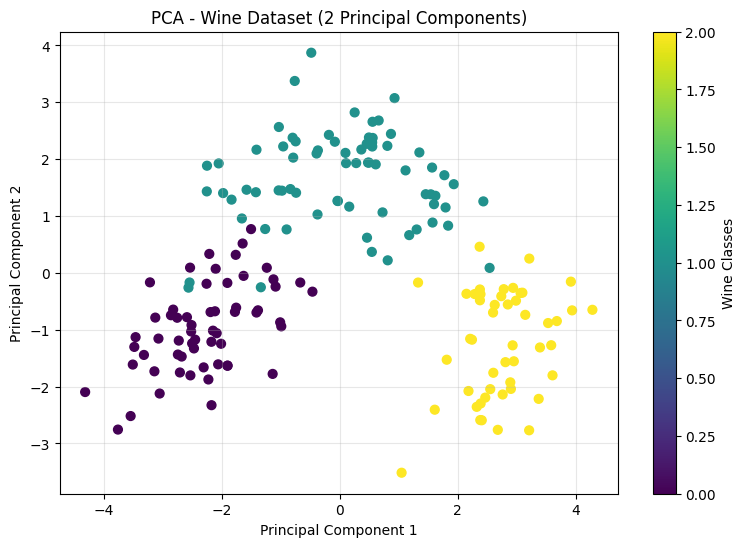

In [12]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap='viridis',
    s=40
)

plt.title("PCA - Wine Dataset (2 Principal Components)")

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.colorbar(label="Wine Classes")

plt.grid(alpha=0.3)

plt.show()

In [13]:
# Calculate explained variance ratio

explained_variance_ratio = (
    eigenvalues / np.sum(eigenvalues)
)

print("Explained Variance Ratio:\n")

print(explained_variance_ratio)

print("\nVariance Retained by First 2 Components:")

print(np.sum(explained_variance_ratio[:2]) * 100, "%")

Explained Variance Ratio:

[0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]

Variance Retained by First 2 Components:
55.40633835693526 %


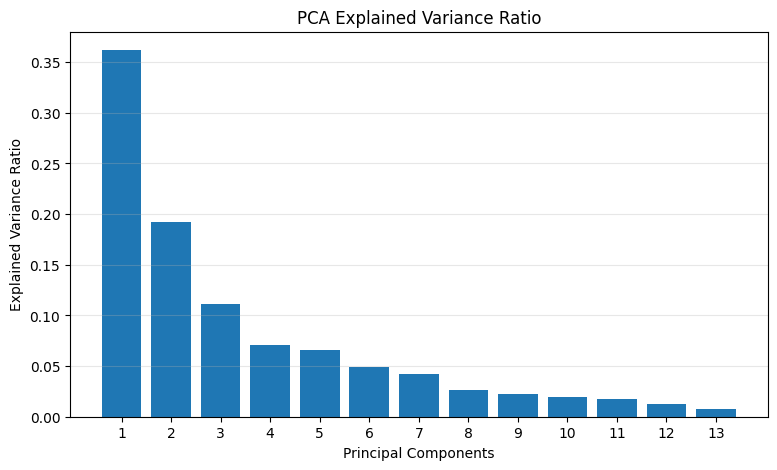

In [14]:
plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(explained_variance_ratio) + 1),
    explained_variance_ratio
)

plt.xlabel("Principal Components")

plt.ylabel("Explained Variance Ratio")

plt.title("PCA Explained Variance Ratio")

plt.xticks(range(1, 14))

plt.grid(axis='y', alpha=0.3)

plt.show()

In [15]:
# Reconstruct data using first two components

X_reconstructed = np.dot(
    X_pca,
    W.T
) + mean

print("Original Data Shape:", X_scaled.shape)

print("Reconstructed Data Shape:", X_reconstructed.shape)

print("\nFirst 5 Reconstructed Samples:\n")

print(X_reconstructed[:5])

Original Data Shape: (178, 13)
Reconstructed Data Shape: (178, 13)

First 5 Reconstructed Samples:

[[ 1.17683758 -0.48854671  0.44943066 -0.80905314  0.90346271  1.40287378
   1.39791791 -0.9486178   1.09629808  0.47110942  0.58106277  1.01020946
   1.47780928]
 [ 0.15764475 -0.61672373 -0.10990684 -0.52523924  0.21383059  0.85030558
   0.93557863 -0.66919329  0.67940854 -0.37249229  0.74867543  0.88597056
   0.51191298]
 [ 0.8619575  -0.3851356   0.32075278 -0.61322768  0.66632506  1.06032437
   1.06095125 -0.72165424  0.8293466   0.32348051  0.45881977  0.77709516
   1.09795087]
 [ 1.87537855 -0.30119251  0.86349723 -0.92833383  1.35937617  1.66203977
   1.57973101 -1.04228148  1.28590532  1.12792641  0.34510016  0.95987296
   2.08315485]
 [ 0.56631018 -0.05171997  0.27285706 -0.25066434  0.40388787  0.45475005
   0.42377954 -0.2761593   0.35040752  0.37160042  0.05647051  0.23643464
   0.60671049]]


In [16]:
# Calculate Mean Squared Error

mse = np.mean(
    (X_scaled - X_reconstructed) ** 2
)

print("Reconstruction Mean Squared Error:")

print(mse)

Reconstruction Mean Squared Error:
0.4459366164306473


In [17]:
# Apply PCA using Scikit-learn

pca = PCA(n_components=2)

X_sklearn = pca.fit_transform(X_scaled)

print("Scikit-learn PCA Results:\n")

print("Reduced Data Shape:", X_sklearn.shape)

print("\nExplained Variance Ratio:")

print(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")

print(np.sum(pca.explained_variance_ratio_) * 100, "%")

Scikit-learn PCA Results:

Reduced Data Shape: (178, 2)

Explained Variance Ratio:
[0.36198848 0.1920749 ]

Total Variance Retained:
55.40633835693526 %


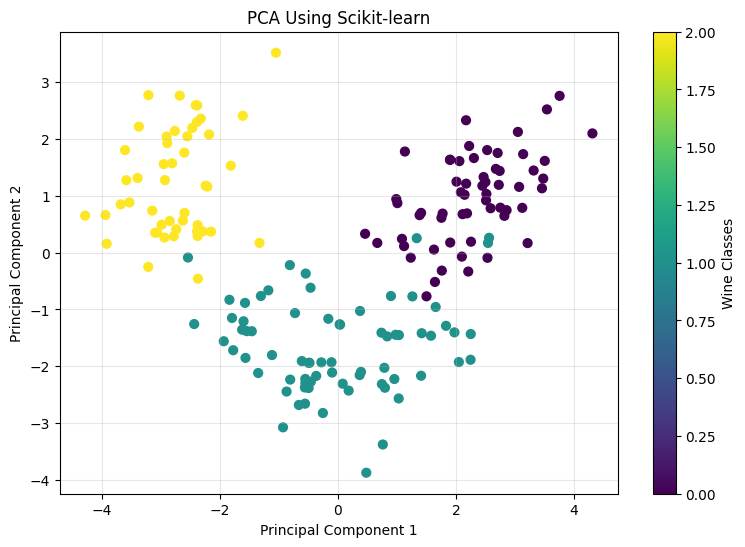

In [18]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_sklearn[:, 0],
    X_sklearn[:, 1],
    c=y,
    cmap='viridis',
    s=40
)

plt.title("PCA Using Scikit-learn")

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.colorbar(label="Wine Classes")

plt.grid(alpha=0.3)

plt.show()

In [19]:
print("PCA From Scratch:")
print(explained_variance_ratio[:2])

print("\nScikit-learn PCA:")
print(pca.explained_variance_ratio_)

print("\nComparison of Total Variance Retained:")

print(
    "From Scratch:",
    round(np.sum(explained_variance_ratio[:2]) * 100, 2),
    "%"
)

print(
    "Scikit-learn:",
    round(np.sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

PCA From Scratch:
[0.36198848 0.1920749 ]

Scikit-learn PCA:
[0.36198848 0.1920749 ]

Comparison of Total Variance Retained:
From Scratch: 55.41 %
Scikit-learn: 55.41 %


In [20]:
print("EXPERIMENT 4: PCA COMPLETED SUCCESSFULLY")

print("\nOriginal Number of Features:", X.shape[1])

print("Reduced Number of Features:", X_pca.shape[1])

print(
    "Variance Retained:",
    round(np.sum(explained_variance_ratio[:2]) * 100, 2),
    "%"
)

print("Reconstruction MSE:", round(mse, 5))

print("\nPCA From Scratch and Scikit-learn Comparison Completed!")

EXPERIMENT 4: PCA COMPLETED SUCCESSFULLY

Original Number of Features: 13
Reduced Number of Features: 2
Variance Retained: 55.41 %
Reconstruction MSE: 0.44594

PCA From Scratch and Scikit-learn Comparison Completed!
